# Phân tích lỗi – khối nghe (ASR) và khối dịch (MT)

Hệ cascade: **PhoWhisper-small** (khối nghe, giữ nguyên) → **VinAI Translate vi2en-v2 + LoRA** (khối dịch; bản cuối **V2**, chọn theo quy tắc DEV – `reports/ablation/QUY_TAC_CHON.md`).
Notebook chỉ đọc kết quả đã chạy (`reports/asr`, `reports/mt`, `reports/domain`, `runs/`) – không chạy model.
Mỗi ca lỗi có **ID bản thu** để nghe lại (`data/clean/audio_16k/fleurs/test/<id>`).

In [1]:
import json, csv, re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Tìm thư mục gốc chứa reports/ (task3/ hoặc experiments/ của repo sản phẩm)
ung_vien = [Path.cwd().parent / "experiments", Path.cwd().parent, Path.cwd(), Path(r"D:\CAIDCM\teamwork\task3")]
BASE = next(c for c in ung_vien if (c / "reports" / "data" / "eda").exists())
R = BASE / "reports"
print("Đọc kết quả từ:", BASE)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
XANH, CAM, XAM, LUC = "#0E7C86", "#B36B00", "#8A939C", "#2E7D32"
doc = lambda p: pd.read_csv(p, encoding="utf-8-sig")
J = lambda p: json.loads(Path(p).read_text(encoding="utf-8"))

Đọc kết quả từ: D:\CAIDCM\teamwork\task3


## 1. WER hai baseline khối nghe

,model,dataset,n_scored,WER_percent,CER_percent,S,D,I,N,rtf
0,PhoWhisper-small,VIVOS,760,6.24,3.25,448,21,13,7722,0.1220
1,PhoWhisper-small,FLEURS_vi_vn,857,13.68,9.88,2057,113,1389,26021,0.0904
2,whisper-small,VIVOS,760,25.99,16.49,1551,136,320,7722,0.1087
3,whisper-small,FLEURS_vi_vn,857,21.24,12.26,4679,291,556,26021,0.0783


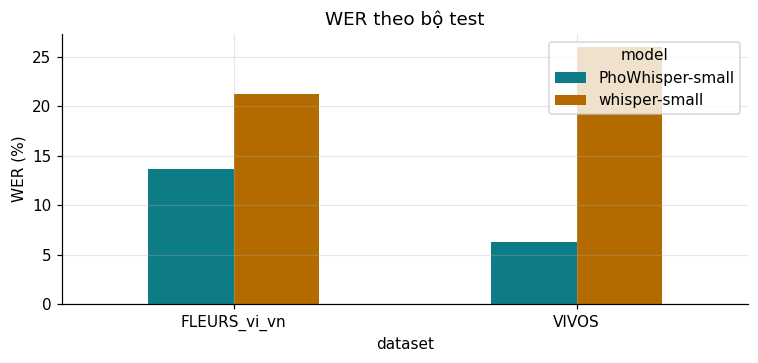

In [2]:
rs = doc(R / "asr/results_task2.csv")[["model", "dataset", "n_scored", "WER_percent", "CER_percent", "S", "D", "I", "N", "rtf"]]
display(rs)
fig, ax = plt.subplots(figsize=(7, 3.4))
p = rs.pivot(index="dataset", columns="model", values="WER_percent"); p.plot.bar(ax=ax, color=[XANH, CAM]); ax.set_ylabel("WER (%)")
ax.tick_params(axis="x", rotation=0); ax.set_title("WER theo bộ test"); plt.tight_layout(); plt.show()

## 2. WER theo nhóm câu (phân tầng) – lỗi tập trung ở đâu

,model,group_type,group_value,n_recordings,S,D,I,WER_percent
2,phowhisper-small,duration_s,<=5,2,1,0,0,3.85
3,phowhisper-small,duration_s,>15_to_30,209,841,57,447,15.24
4,phowhisper-small,duration_s,>30,7,44,2,401,94.70
5,phowhisper-small,duration_s,>5_to_15,639,1171,54,541,10.58
6,phowhisper-small,name_or_number,name,552,1581,91,1219,16.52
7,phowhisper-small,name_or_number,neither,278,392,17,40,5.89
8,phowhisper-small,name_or_number,number,171,723,24,759,27.43
11,whisper-small,duration_s,<=5,2,5,0,0,19.23
12,whisper-small,duration_s,>15_to_30,209,1646,117,166,21.85
13,whisper-small,duration_s,>30,7,95,3,37,28.60


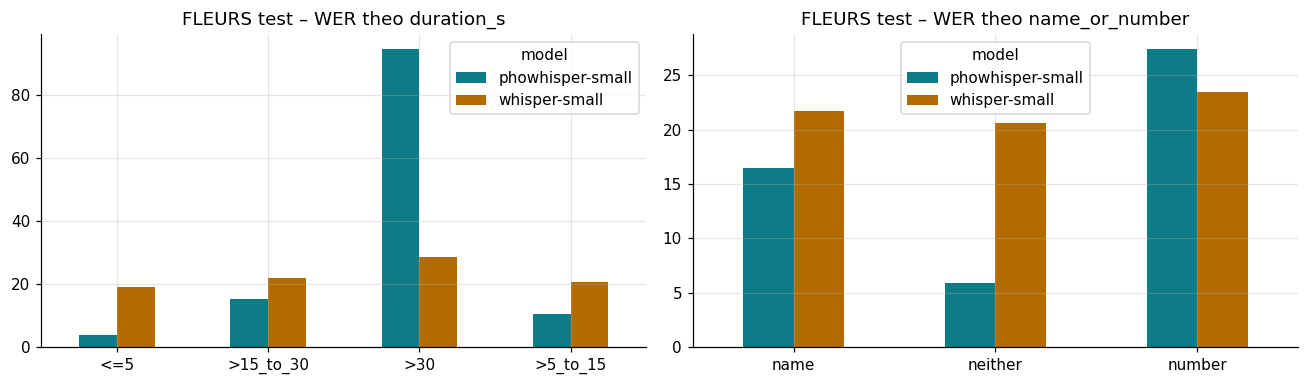

Câu có chữ số: phần lớn lỗi là CHÈN từ (số đọc thành chữ: '802' → 'tám không hai') – lỗi do cách viết tham chiếu, không hẳn do nghe sai.


In [3]:
st = doc(R / "asr/strata.csv")
st = st[st.run_id.str.contains("fleurs_test")].assign(model=lambda d: d.run_id.str.extract(r"t2_(.*)_fleurs")[0])
display(st[["model", "group_type", "group_value", "n_recordings", "S", "D", "I", "WER_percent"]])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, gt_ in zip(ax, ("duration_s", "name_or_number")):
    d = st[st.group_type == gt_].pivot(index="group_value", columns="model", values="WER_percent"); d.plot.bar(ax=a, color=[XANH, CAM])
    a.set_title(f"FLEURS test – WER theo {gt_}"); a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print("Câu có chữ số: phần lớn lỗi là CHÈN từ (số đọc thành chữ: '802' → 'tám không hai') – lỗi do cách viết tham chiếu, không hẳn do nghe sai.")

## 3. Ma trận nhầm dấu thanh

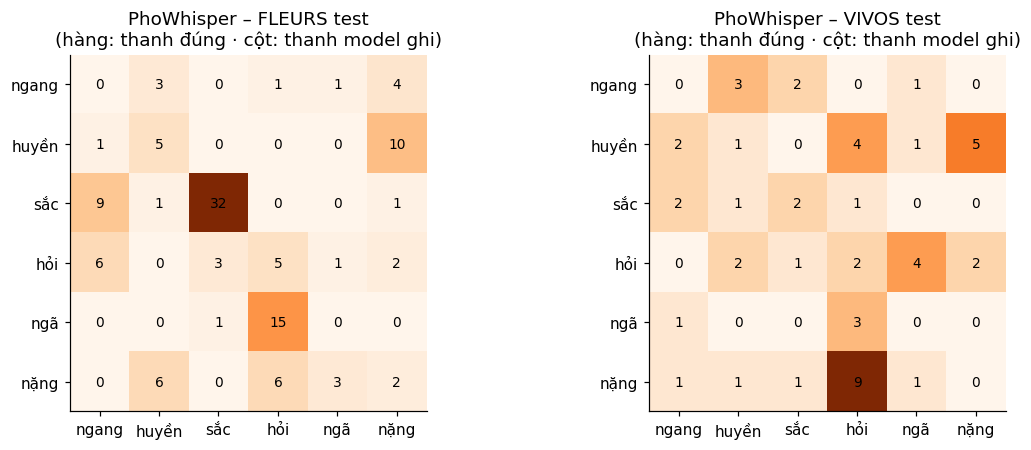

In [4]:
import numpy as np
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (ten, f) in zip(ax, (("FLEURS test", "tone_confusion_kiet_t2_phowhisper-small_fleurs_test.csv"), ("VIVOS test", "tone_confusion_kiet_t2_phowhisper-small_vivos_test.csv"))):
    m = doc(R / "asr" / f).set_index("ref\\hyp"); a.imshow(m.values, cmap="Oranges")
    a.set_xticks(range(len(m.columns))); a.set_xticklabels(m.columns); a.set_yticks(range(len(m.index))); a.set_yticklabels(m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]): a.text(j, i, m.values[i, j], ha="center", va="center", fontsize=9)
    a.set_title(f"PhoWhisper – {ten}\n(hàng: thanh đúng · cột: thanh model ghi)"); a.grid(False)
plt.tight_layout(); plt.show()

## 4. Audio dài hơn 30 giây (long-form)

In [5]:
lf = doc(R / "asr/long_form_audit.csv"); lf["model"] = lf.run_id.str.extract(r"t2_(.*)_fleurs")[0]
display(lf[["model", "id", "duration_s", "n_segments", "hit_cap_440", "n_output_tokens", "S", "D", "I", "N", "WER_percent"]])
print("PhoWhisper đưa thẳng cả file > 30 s: chèn rất nhiều từ (lặp 'a. a. a.', 'từng từng…') → sản phẩm chia đoạn ≤ 28 s trước khi nhận dạng.")
he = next((R / d / "ket_qua.json" for d in ("he_thong_V2", "he_thong") if (R / d / "ket_qua.json").exists()), R / "x")
if he.exists():
    k = J(he); print("Sản phẩm (chia đoạn) – nhóm audio dài:", {c: k[c]["dai"] for c in ("truoc_0411", "proposed")})

,model,id,duration_s,n_segments,hit_cap_440,n_output_tokens,S,D,I,N,WER_percent
0,phowhisper-small,1988769089134997232.wav,30.48,2,False,184,2,0,24,71,36.6
1,phowhisper-small,15135508090217618875.wav,31.32,2,True,557,6,0,14,61,32.8
2,phowhisper-small,15988068266071045826.wav,32.22,2,False,193,6,1,24,70,44.3
3,phowhisper-small,8180761900974663168.wav,33.12,2,False,417,6,0,138,70,205.7
4,phowhisper-small,7777625010460801495.wav,33.06,2,True,565,7,1,31,74,52.7
5,phowhisper-small,11806133943011932690.wav,38.10,2,False,138,11,0,4,63,23.8
6,phowhisper-small,5732900245807707573.wav,36.42,3,True,577,6,0,166,63,273.0
7,whisper-small,1988769089134997232.wav,30.48,3,False,153,5,0,17,71,31.0
8,whisper-small,15135508090217618875.wav,31.32,2,False,120,10,0,3,61,21.3
9,whisper-small,15988068266071045826.wav,32.22,3,False,148,16,2,4,70,31.4


PhoWhisper đưa thẳng cả file > 30 s: chèn rất nhiều từ (lặp 'a. a. a.', 'từng từng…') → sản phẩm chia đoạn ≤ 28 s trước khi nhận dạng.
Sản phẩm (chia đoạn) – nhóm audio dài: {'truoc_0411': {'n': 10, 'WER_asr': 16.03, 'CER_asr': 12.04, 'WER_sau_doi_so': 16.03, 'RTF': 0.1008, 'BLEU': 15.51, 'chrF++': 49.61, 'bleu_signature': 'nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.4.3'}, 'proposed': {'n': 10, 'WER_asr': 15.59, 'CER_asr': 10.99, 'WER_sau_doi_so': 12.94, 'RTF': 0.1038, 'BLEU': 18.74, 'chrF++': 51.34, 'bleu_signature': 'nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.4.3'}}


## 5. Giả thuyết Gap Analysis

In [6]:
gh = doc(R / "asr/gap_hypotheses.csv"); display(gh[["id", "hypothesis", "status", "ket_qua_kiet"]].rename(columns={"ket_qua_kiet": "ket_qua"}))

,id,hypothesis,status,ket_qua
0,H1,Miền và độ dài góp phần làm WER khác giữa VIVOS và FLEURS,CO_BANG_CHUNG,"PhoWhisper VIVOS 6,24% vs FLEURS 13,68%; FLEURS chỉ tính ≤ 30 s vẫn 12,18%. WER FLEURS tăng theo độ dài: 5–15 s 10,5..."
1,H2,Sai khác chuẩn hóa số gây phần đáng kể gap,MOT_PHAN,"Câu có chữ số: WER 27,43% (chèn 759) vs câu không tên/số 5,89%. Nghe kiểm mục 10: người đọc nói 'tám không hai' cho ..."
2,H3,Checkpoint chuyên tiếng Việt giảm lỗi dấu và tên riêng,CO_BANG_CHUNG,"Ghép cặp cùng ID, bootstrap cụm 1000 lần: Whisper − PhoWhisper = +19,75 [15,00; 28,06] (VIVOS), +7,56 [5,26; 9,83] (..."
3,H4,Beam 5 và greedy có khác biệt chất lượng tốc độ,DA_KIEM,"FLEURS dev, chỉ đổi num_beams: bản thu ≤ 30 s PhoWhisper beam 5/1 = 10,70/10,91; Whisper 19,90/27,82 (beam 1 có 2 bả..."
4,H5,Cắt audio hoặc giới hạn token làm tăng thiếu từ,KHONG_UNG_HO,"7/7 bản > 30 s có output, coverage phủ hết audio, không cắt 30 s; nhóm > 30 s: D = 2, I = 401 / N = 472 → lỗi là CHÈ..."


## 6. Ca lỗi khối nghe có ID để nghe lại

In [7]:
ea = doc(R / "asr/error_audit.csv")
cot = ["recording_id", "duration_s", "WER_percent", "tone_only", "omission", "proper_name", "number", "repetition", "audio_checked", "reference_raw", "hypothesis_raw"]
ea_p = ea[ea.run_id.str.contains("phowhisper") & ea.run_id.str.contains("fleurs")]
display(ea_p.sort_values("WER_percent", ascending=False)[cot].head(12))
loai = ["tone_only", "omission", "proper_name", "number", "repetition"]
dem = {c: int(ea_p[c].astype(str).str.lower().isin(["1", "true", "yes", "co"]).sum()) for c in loai}
print("Số ca được gắn nhãn theo loại lỗi (trong", len(ea_p), "ca audit):", dem)
nk = BASE / "nghe_kiem/danh_sach_nghe_kiem.csv"
if nk.exists():
    print("\nNghe kiểm bằng tai:"); display(doc(nk).iloc[:, :8])

,recording_id,duration_s,WER_percent,tone_only,omission,proper_name,number,repetition,audio_checked,reference_raw,hypothesis_raw
0,5732900245807707573.wav,36.42,273.015873,0,0,1,0,1,CHUA_NGHE,"""Đặc tính nhiệt của chúng không ổn định như các hang động lớn trên Trái Đất vốn thường duy trì nhiệt độ khá ổn định,...",đặc tính nhiệt của chúng không ổn định như các hang động lớn trên trái đất vốn thường duy trì nhiệt độ khá ổn định n...
1,8180761900974663168.wav,33.12,205.714286,0,0,1,0,1,CHUA_NGHE,Trang web tin tức giải trí TMZ được biết người phóng viên ảnh đã ngừng xe ở phía bên kia đường Sepulveda Boulevard v...,trang web tin tức giải trí tia em dép được biết người phóng viên ảnh đã ngừng xe ở phía bên kia đường serbia venice ...
2,6107287179341969730.wav,10.86,117.647059,0,0,1,1,0,CHUA_NGHE,Chuẩn 802.11n hoạt động trên cả hai tần số 2.4 Ghz và 5.0 Ghz.,chuẩn tám không hai chấm một một in lời hoạt động trên cả hai tần số hai chấm bốn đi ra hệ và năm chấm không đi ra hệ.
3,17744918915672998950.wav,11.64,111.764706,0,0,1,1,0,CHUA_NGHE,Chuẩn 802.11n hoạt động trên cả hai tần số 2.4 Ghz và 5.0 Ghz.,chuẩn tám không hai chấm một một n hoạt động trên cả hai tần số hai chấm bốn ghi ra hệt và năm chấm không ghi ra hệt.
4,2326491111869531028.wav,12.84,111.764706,0,0,1,1,0,CHUA_NGHE,Chuẩn 802.11n hoạt động trên cả hai tần số 2.4 Ghz và 5.0 Ghz.,chuẩn tám không hai chấm một một n hoạt động trên cả hai tần số hai chấm bốn ghi a hẹp và năm chấm không ghi a hẹp.
5,15207612342643622159.wav,12.78,93.333333,0,0,1,0,0,CHUA_NGHE,Lakkha Singh cũng trình bày chhappan bhog bhajan. Ca kĩ Raju Khandelwal hát cùng ông.,lắp ca xin cũng trình bày chắp banh bong ba han ca sĩ gây du khăn đeo bót hát cùng ông.
6,13884391343743752501.wav,10.20,86.666667,0,0,1,1,0,CHUA_NGHE,Rolando Mendoza đã bắn vào các du khách bằng khẩu súng trường M16 của hắn.,gâu lan đô men dô ra đã bóng vào cái du khách bằng khẩu súng trường mà mười sáu có hát.
7,14566257005506189223.wav,13.08,86.666667,0,0,1,0,0,CHUA_NGHE,Lakkha Singh cũng trình bày chhappan bhog bhajan. Ca kĩ Raju Khandelwal hát cùng ông.,lát kha xin cũng trình bày chắp ranh không hazard ca sĩ gây du khăn đeo góc hát cùng ông.
8,14749734800013766761.wav,17.82,82.352941,0,1,0,1,1,CHUA_NGHE,"Điều này cho phép nó có khả năng tương thích ngược với 802.11a, 802.11b và 802.11g, với điều kiện các trạm cơ sở có ...",điều này cho phép nó có khả năng tương thích ngược với tám trăm linh hai chấm mười một a tám trăm linh hai chấm mười...
9,5186354191609042169.wav,21.06,73.529412,0,1,0,1,1,CHUA_NGHE,"Điều này cho phép nó có khả năng tương thích ngược với 802.11a, 802.11b và 802.11g, với điều kiện các trạm cơ sở có ...",điều này cho phép nó có khả năng tương thích ngược với tám không hai phẩy mười một a tám không hai phẩy mười một bê ...


Số ca được gắn nhãn theo loại lỗi (trong 35 ca audit): {'tone_only': 8, 'omission': 8, 'proper_name': 31, 'number': 21, 'repetition': 9}

Nghe kiểm bằng tai:


,stt,muc_dich,dataset,recording_id,file_nghe,duong_dan_goc_model_dung,thoi_luong_s,giay_cuoi_co_tieng_do_tin_hieu
0,1,Bản thu dài > 30 s: có ảo giác ở đoạn cuối không?,FLEURS vi_vn test,1988769089134997232.wav,audio/01_fleurs_1988769089134997232.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\1988769089134997232.wav,30.48,28.5
1,2,Bản thu dài > 30 s: có ảo giác ở đoạn cuối không?,FLEURS vi_vn test,15135508090217618875.wav,audio/02_fleurs_15135508090217618875.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\15135508090217618875.wav,31.32,28.5
2,3,Bản thu dài > 30 s: có ảo giác ở đoạn cuối không?,FLEURS vi_vn test,15988068266071045826.wav,audio/03_fleurs_15988068266071045826.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\15988068266071045826.wav,32.22,32.0
3,4,Bản thu dài > 30 s: có ảo giác ở đoạn cuối không?,FLEURS vi_vn test,7777625010460801495.wav,audio/04_fleurs_7777625010460801495.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\7777625010460801495.wav,33.06,33.0
4,5,Bản thu dài > 30 s: có ảo giác ở đoạn cuối không?,FLEURS vi_vn test,8180761900974663168.wav,audio/05_fleurs_8180761900974663168.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\8180761900974663168.wav,33.12,33.0
5,6,Bản thu dài > 30 s: có ảo giác ở đoạn cuối không?,FLEURS vi_vn test,5732900245807707573.wav,audio/06_fleurs_5732900245807707573.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\5732900245807707573.wav,36.42,36.0
6,7,Bản thu dài > 30 s: có ảo giác ở đoạn cuối không?,FLEURS vi_vn test,11806133943011932690.wav,audio/07_fleurs_11806133943011932690.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\11806133943011932690.wav,38.10,38.0
7,8,Trường hợp 1 (slide 7): lỗi dấu thanh – người nói đọc dấu nào?,VIVOS test,VIVOSDEV10_239,audio/08_vivos_VIVOSDEV10_239.wav,D:\CAIDCM\teamwork\task3\data\vivos\audio\vivos\test\waves\VIVOSDEV10\VIVOSDEV10_239.wav,1.88,1.5
8,9,Trường hợp 2 (slide 7): tên riêng – người nói đọc tên thế nào?,FLEURS vi_vn test,15207612342643622159.wav,audio/09_fleurs_15207612342643622159.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\15207612342643622159.wav,12.78,11.5
9,10,Số: người nói đọc số thế nào (vd 'hai nghìn' hay 'hai ngàn')?,FLEURS vi_vn test,6107287179341969730.wav,audio/10_fleurs_6107287179341969730.wav,D:\CAIDCM\teamwork\task3\data\clean\audio_16k\fleurs\test\6107287179341969730.wav,10.86,9.5


## 7. Khối dịch – BLEU theo nhóm câu trên dev (B0 → V1…V4)

hệ,nhóm,n,B0,V1,V2,V3,V4
0,ASR sai nhiều (WER ≥ 30%),31,7.86,16.01,15.69,16.67,13.05
1,còn lại,120,27.26,28.10,27.26,29.37,28.76
2,có chữ số,44,10.86,18.29,18.78,18.95,17.69
3,có tên riêng,210,20.30,25.26,25.28,24.82,24.17
4,lời ASR > 40 từ,54,16.55,22.54,22.44,21.68,21.54
5,tất cả,361,22.96,26.47,26.45,26.71,26.33


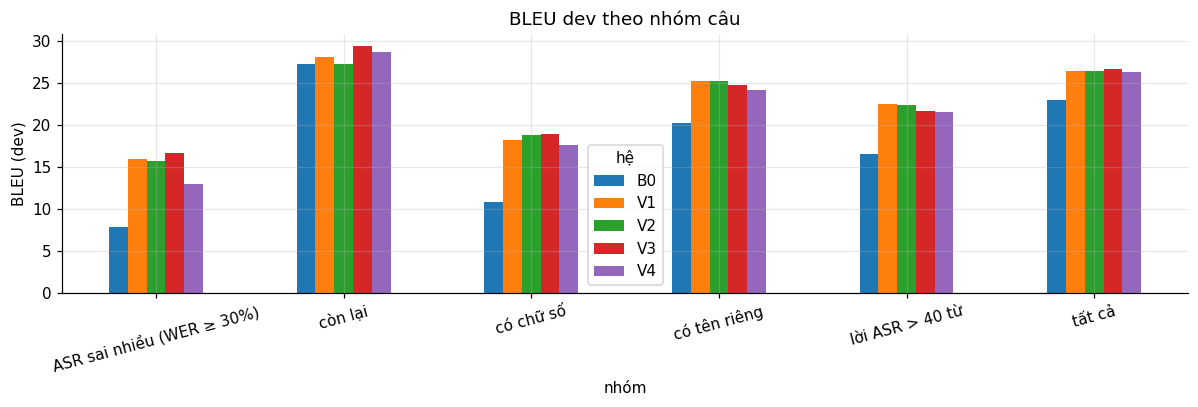

LoRA tăng mạnh nhất ở nhóm khối nghe làm sai (có số, ASR sai nhiều, câu dài); nhóm 'còn lại' gần như không đổi.


In [8]:
nhom = {"all": "tất cả", "so": "có chữ số", "ten": "có tên riêng", "dai": "lời ASR > 40 từ", "asr_xau": "ASR sai nhiều (WER ≥ 30%)", "con_lai": "còn lại"}
rows = []
for v in ("V1", "V2", "V3", "V4"):
    f = R / f"mt/failure_{v}_dev.json"
    if f.exists():
        g = J(f)["groups"]
        for k, ten in nhom.items():
            if k in g:
                if v == "V1": rows.append({"nhóm": ten, "n": g[k]["n"], "hệ": "B0", "BLEU": g[k]["B0"][0]})
                rows.append({"nhóm": ten, "n": g[k]["n"], "hệ": v, "BLEU": g[k][v][0]})
bd = pd.DataFrame(rows).pivot_table(index=["nhóm", "n"], columns="hệ", values="BLEU").reset_index(); display(bd)
fig, ax = plt.subplots(figsize=(11, 3.8)); bd.set_index("nhóm")[["B0", "V1", "V2", "V3", "V4"]].plot.bar(ax=ax)
ax.set_ylabel("BLEU (dev)"); ax.tick_params(axis="x", rotation=15); ax.set_title("BLEU dev theo nhóm câu"); plt.tight_layout(); plt.show()
print("LoRA tăng mạnh nhất ở nhóm khối nghe làm sai (có số, ASR sai nhiều, câu dài); nhóm 'còn lại' gần như không đổi.")

## 8. Kết quả theo miền (FLoRes+) – trọng tâm Giáo dục

he,B0,V1,V2,V3,V4
mien,,,,,
Du lịch,21.69,26.91,26.95,25.32,26.42
Giáo dục,26.56,30.84,31.45,30.92,31.22
Tin tức,18.47,22.99,22.51,23.17,22.30


,mien,n_ban_thu,WER,CER
3,Giáo dục (Wikibooks – sách giáo khoa mở),336,10.76,8.00
4,Tin tức (Wikinews),267,19.18,14.13
5,Du lịch (Wikivoyage),254,11.60,7.65


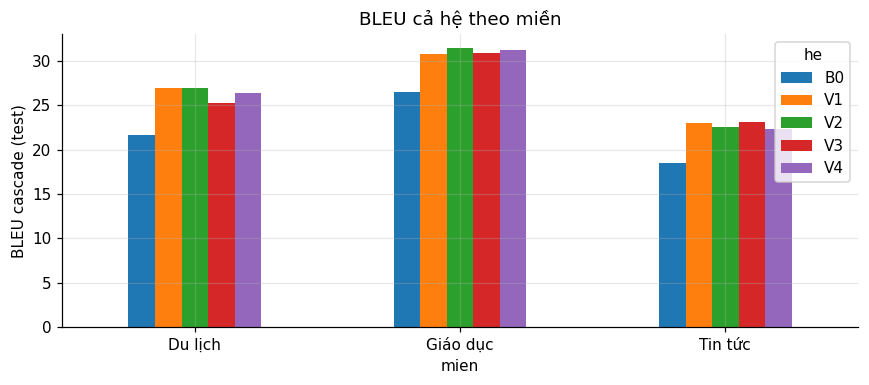

In [9]:
dm = doc(R / "domain/ket_qua_theo_mien.csv")
mt_ = dm[(dm.khoi == "MT") & (dm.tap == "fleurs_test_asr_pho")].assign(mien=lambda d: d.mien.str.split(" \\(").str[0])
p = mt_.pivot(index="mien", columns="he", values="BLEU")[["B0", "V1", "V2", "V3", "V4"]]; display(p)
asr = dm[(dm.khoi == "ASR") & (dm.he == "phowhisper-small_fleurs_test")][["mien", "n_ban_thu", "WER", "CER"]]; display(asr)
fig, ax = plt.subplots(figsize=(8, 3.6)); p.plot.bar(ax=ax); ax.set_ylabel("BLEU cascade (test)"); ax.tick_params(axis="x", rotation=0)
ax.set_title("BLEU cả hệ theo miền"); plt.tight_layout(); plt.show()

## 9. Ca dịch có ID: bản cuối tốt hơn / kém hơn B0 nhiều nhất (FLEURS test, chrF++ từng câu)

In [10]:
import sacrebleu
L = lambda v: {(r := json.loads(l))["id"]: r for l in open(BASE / f"runs/mt/{v}/fleurs_test_asr_pho/hyp.jsonl", encoding="utf-8")}
BC = J(R / "ablation/chon_ban_cuoi.json")["ban_chon"]; print("Bản cuối:", BC)
A, B = L("B0"), L(BC); ch = sacrebleu.CHRF(word_order=2)
d = pd.DataFrame([{"id": i, "chrF_B0": ch.sentence_score(A[i]["hyp"], [A[i]["ref"]]).score, "chrF_cuoi": ch.sentence_score(B[i]["hyp"], [B[i]["ref"]]).score,
                   "loi_ASR": A[i]["src"], "tham_chieu": A[i]["ref"], "B0": A[i]["hyp"], "ban_cuoi": B[i]["hyp"]} for i in A])
d["delta"] = d.chrF_cuoi - d.chrF_B0
print(f"{BC} tốt hơn B0 ở {(d.delta > 0).sum()} câu, kém hơn ở {(d.delta < 0).sum()} câu, bằng nhau {(d.delta == 0).sum()} (trên {len(d)} bản thu).")
display(Markdown(f"**{BC} tốt hơn nhiều nhất**")); display(d.sort_values("delta", ascending=False).head(5).round(1))
display(Markdown(f"**{BC} kém hơn nhiều nhất** – không phải câu nào phương pháp cũng thắng")); display(d.sort_values("delta").head(5).round(1))

Bản cuối: V2


V2 tốt hơn B0 ở 556 câu, kém hơn ở 265 câu, bằng nhau 36 (trên 857 bản thu).


**V2 tốt hơn nhiều nhất**

,id,chrF_B0,chrF_cuoi,loi_ASR,tham_chieu,B0,ban_cuoi,delta
853,8180761900974663168.wav,1.2,50.2,trang web tin tức giải trí tia em dép được biết người phóng viên ảnh đã ngừng xe ở phía bên kia đường serbia venice ...,Entertainment news website TMZ understands the photographer stopped his vehicle on the other side of Sepulveda Boule...,A. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a. a....,The entertainment news website Tia Emdep reported that the photographer stopped the vehicle on the other side of the...,49.0
631,12507985491009086913.wav,37.7,79.8,các đề cử khác bao gồm phim đạo diễn quay phim thiết kế trang phục biên tập phim nhạc phim gốc thiết kế sản xuất biê...,"The other nominations include Best Picture, Director, Cinematography, Costume Design, Film-editing, Original Score, ...",Other nominations included film director filming costume design film editing original soundtrack production design s...,"Other nominations included Best Film, Director, Cinematographer, Costume Design, Film Editing, Original Score, Produ...",42.1
54,2038167404924633032.wav,26.8,58.6,sau khi chiến sự nổ ra nước anh đã triển khai phong tỏa ngay hải quân đức.,"Soon after the outbreak of hostilities, Britain initiated a naval blockade of Germany.","After the war broke out, england deployed a blockade on the german navy.","Following the outbreak of hostilities, Britain immediately deployed a blockade on the German navy.",31.8
162,11453833847884158456.wav,33.0,63.8,chấp nhận là quan điểm của arizona về tất cả mọi vấn đề liên quan đến khoa học kể cả tâm lý học.,"Accepted were Aristotle's views on all matters of science, including psychology.",acceptance is arizona's view on everything from science to psychology.,"Acceptance is Arizona's view on all matters related to science, including psychology.",30.8
44,14798044245039786985.wav,30.6,60.9,vậy là có khả năng chú thích được thêm vào đơn giản chỉ là nhãn đánh dấu.,"So, it is likely that the notation was added simply as a label.",So there's a possibility that the footnotes are simply labels.,"Thus, it is possible that the annotation was added simply as a tick mark.",30.3


**V2 kém hơn nhiều nhất** – không phải câu nào phương pháp cũng thắng

,id,chrF_B0,chrF_cuoi,loi_ASR,tham_chieu,B0,ban_cuoi,delta
163,5112472991553410708.wav,59.9,38.2,giancalo trichangia mắc kiểm soát chiếc xe công mạch và kết thúc cột đô rất sớm sau khi bắt đầu.,Giancarlo Fisichella lost control of his car and ended the race very soon after the start.,giancalo trichangia caught control of the circuit car and ended the capital column very soon after the start.,Christopher Trichurch took control of the circuit breaker and finished the tower early after the start.,-21.7
428,12740622559749389835.wav,52.4,32.2,sau khi đập được xây vào năm một ngàn chín trăm sáu ba lũ theo mùa bình thường sẽ đưa vù sa đi hết chiều dài song đã...,"After the dam was built in 1963, the seasonal floods that would spread sediment throughout the river were halted.","After the dam was built in the year one thousand nine hundred and six, the three normal seasonal floods that would h...","Following the dam's construction in 2006, three normal seasonal floods would have taken the entire length of the lag...",-20.2
13,9030879651488261615.wav,43.9,27.2,những cặp đôi này đã quyết định nên kế hoạch nhận con nuôi.,These couples may choose to make an adoption plan for their baby.,These couples have decided on an adoption plan.,These couples have decided to adopt.,-16.7
61,2780052677995190694.wav,49.6,33.7,hãy nghĩ hành trình trượt tuyết tương tự như một hành trình để bộ đường dài.,Think of the skiing route as of a similar hiking route.,Think of the journey of skiing as similar to a journey to hiking.,Think of skiing as a journey to hiking.,-15.9
8,10751146797584417593.wav,73.8,58.2,nó mỏng hơn dưới vùng marina biển và dày hơn ở vùng cao.,It is thinner under the maria and thicker under the highlands.,it is thinner under the marine marina and thicker in the highlands.,It is thinner below the coast and thicker in the highlands.,-15.7


## 10. Lỗi giữ số: tham chiếu có chữ số mà bản dịch không giữ đúng

In [11]:
so = lambda s: set(re.findall(r"\d+", s))
co = d[d.tham_chieu.map(lambda s: bool(so(s)))]
mat = {h: int((~co.apply(lambda r: so(r.tham_chieu) <= so(r[h]), axis=1)).sum()) for h in ("B0", "ban_cuoi")}
print(f"{len(co)} bản thu có chữ số trong tham chiếu; số bản dịch thiếu/sai số: B0 {mat['B0']}, {BC} {mat['ban_cuoi']}")
vd = co[~co.apply(lambda r: so(r.tham_chieu) <= so(r.ban_cuoi), axis=1)].head(6)[["id", "loi_ASR", "tham_chieu", "ban_cuoi"]]; display(vd)
print("Khối nghe đọc số bằng chữ nên khối dịch phải đoán lại chữ số; sản phẩm thêm bước đổi số trước khi dịch (src/so.py) – đo ở reports/he_thong_V2.")

165 bản thu có chữ số trong tham chiếu; số bản dịch thiếu/sai số: B0 163, V2 110


,id,loi_ASR,tham_chieu,ban_cuoi
94,9061310288361763985.wav,ronaldo manila đã bắn vào các du khách bằng khẩu súng trường mò mười sáu của hắn.,Rolando Mendoza fired his M16 rifle at the tourists.,Ronaldo Manil shot at the tourists with his sixteen-caliber rifle.
110,1184420591726507420.wav,tới mười một giờ ba mươi lăm tối đội cứu hỏa cuối cùng đã dùng nước dập được đám cháy.,Fire rescue crews eventually doused the fire by 11:35 pm.,"By 1135 p.m., the fire department had finally put out the fire with water."
111,1915781512999315916.wav,tới mười một giờ ba mươi lăm tối đợt cứu hỏa cuối cùng đã dùng nước dập được đám cháy.,Fire rescue crews eventually doused the fire by 11:35 pm.,"By 1135 p.m., the last firefighting operation had put out the fire with water."
118,13884391343743752501.wav,gâu lan đô men dô ra đã bóng vào cái du khách bằng khẩu súng trường mà mười sáu có hát.,Rolando Mendoza fired his M16 rifle at the tourists.,Georgian Douglass hit the tourist with a rifle with which he was singing.
121,14122232668905635400.wav,xe buýt cót tết số bốn trăm linh ba thường xuyên chạy đến sinh tra dừng ở kabul de roca.,"Scotturb Bus 403 travels regularly to Sintra, stopping at Cabo da Roca.","New Year's eve bus 4003 regularly runs to a stop in Kabul, Rwanda."
125,3887186793104542535.wav,xe buýt scotland số bốn trăm linh ba thường xuyên chạy đến shincha dừng ở kabul yayaoka.,"Scotturb Bus 403 travels regularly to Sintra, stopping at Cabo da Roca.","Scottish Bus 4003 regularly runs to Shincha, stopping in Osaka."


Khối nghe đọc số bằng chữ nên khối dịch phải đoán lại chữ số; sản phẩm thêm bước đổi số trước khi dịch (src/so.py) – đo ở reports/he_thong_V2.


## 11. Lỗi lan truyền từ khối nghe sang khối dịch

,n,chrF_B0,chrF_cuoi
nhom_WER,,,
0%,183,55.39,59.43
0–10%,281,52.79,55.96
10–30%,301,47.01,49.45
> 30%,92,36.48,42.67


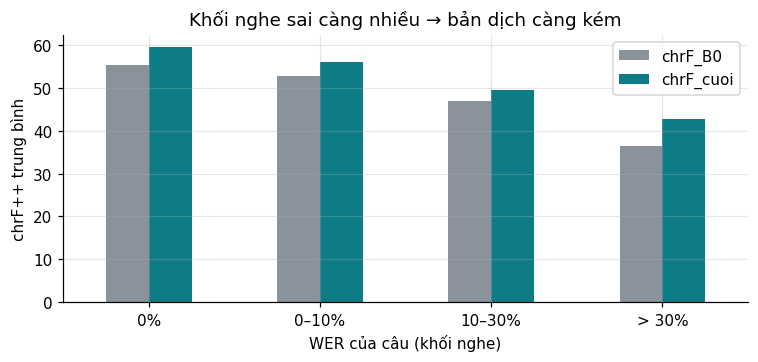

LoRA lấy lại được một phần, nhưng lỗi nghe nặng vẫn kéo bản dịch xuống – nhược điểm cố hữu của cascade.


In [12]:
pr = {json.loads(l)["id"]: json.loads(l) for l in open(BASE / "runs/asr/kiet_t2_phowhisper-small_fleurs_test/predictions.jsonl", encoding="utf-8")}
from collections import Counter
sys_path = BASE / "scripts" / "asr"
import sys; sys.path.insert(0, str(sys_path))
from score_asr import score
d["WER_cau"] = [100 * (lambda c: (c["S"] + c["D"] + c["I"]) / max(c["N"], 1))(score(pr[i]["reference"], pr[i]["prediction"])["word_counts"]) for i in d.id]
d["nhom_WER"] = pd.cut(d.WER_cau, [-.1, 0, 10, 30, 1e9], labels=["0%", "0–10%", "10–30%", "> 30%"])
t = d.groupby("nhom_WER", observed=True).agg(n=("id", "size"), chrF_B0=("chrF_B0", "mean"), chrF_cuoi=("chrF_cuoi", "mean")).round(2); display(t)
fig, ax = plt.subplots(figsize=(7, 3.4)); t[["chrF_B0", "chrF_cuoi"]].plot.bar(ax=ax, color=[XAM, XANH]); ax.set_xlabel("WER của câu (khối nghe)")
ax.set_ylabel("chrF++ trung bình"); ax.tick_params(axis="x", rotation=0); ax.set_title("Khối nghe sai càng nhiều → bản dịch càng kém"); plt.tight_layout(); plt.show()
print("LoRA lấy lại được một phần, nhưng lỗi nghe nặng vẫn kéo bản dịch xuống – nhược điểm cố hữu của cascade.")

## 12. Baseline B1 – Whisper Translate end-to-end (không có transcript tiếng Việt → không tính WER)

In [13]:
pb = BASE / "runs/b1/predictions_b1.jsonl"
if not pb.exists():
    print("NOT RUN: chưa có runs/b1/predictions_b1.jsonl (chạy notebooks/02_baseline_B1_whisper_translate.ipynb)")
else:
    b1 = pd.read_json(pb, lines=True, dtype={"sample_id": str, "sent_id": str})
    sc = J(BASE / "runs/mt/B1_whisper-small_translate/fleurs_test_audio/score.json")
    print(f"B1: BLEU {sc['BLEU']} · chrF++ {sc['chrF++']} · RTF {sc['RTF_tong']} (n = {sc['n']}) | B0 cascade: BLEU {J(BASE / 'runs/mt/B0/fleurs_test_asr_pho/score.json')['BLEU']}")
    b1["tu_du_doan"] = b1.pred_en.str.split().str.len(); b1["tu_tham_chieu"] = b1.reference_en.str.split().str.len()
    b1["lap_vong"] = b1.tu_du_doan > 2 * b1.tu_tham_chieu
    bl = lambda g: round(sacrebleu.corpus_bleu(list(g.pred_en), [list(g.reference_en)]).score, 2)
    t = pd.DataFrame([{"nhóm": k, "n": len(g), "BLEU": bl(g), "câu lặp vòng": int(g.lap_vong.sum())} for k, g in
                      [("toàn bộ", b1)] + [(f"miền {k}", g) for k, g in b1.groupby("domain")] + [("≤ 30 s", b1[~b1.long_form]), ("> 30 s", b1[b1.long_form])]])
    display(t)
    print(f"{int(b1.lap_vong.sum())} câu dài hơn 2 lần câu tham chiếu (giải mã lặp vòng, vd 'network network network…'); "
          f"bỏ các câu này BLEU = {bl(b1[~b1.lap_vong])} – chỉ để chẩn đoán, số báo cáo vẫn là {sc['BLEU']}.")
    display(b1[b1.lap_vong].nlargest(3, "tu_du_doan")[["sample_id", "audio_duration_s", "tu_du_doan", "pred_en"]].assign(pred_en=lambda x: x.pred_en.str[:160]))
    for f in sorted((BASE / "reports/mt").glob("bootstrap_*_vs_B1.json")):
        r = J(f); print(f"{f.stem}: {r['BLEU_A']} → B1 {r['BLEU_B']}, Δ {r['delta']:+.2f} [{r['ci95'][0]}; {r['ci95'][1]}]")
    so_ = lambda s: set(re.findall(r"\d+", s))
    co_ = b1[b1.reference_en.map(lambda s: bool(so_(s)))]
    print(f"Giữ đúng chữ số: {len(co_)} câu có số trong tham chiếu → B1 sai/thiếu {int((~co_.apply(lambda r: so_(r.reference_en) <= so_(r.pred_en), axis=1)).sum())} câu")

B1: BLEU 3.8 · chrF++ 25.45 · RTF 0.137 (n = 857) | B0 cascade: BLEU 22.69


,nhóm,n,BLEU,câu lặp vòng
0,toàn bộ,857,3.80,86
1,miền du_lich,254,4.23,25
2,miền giao_duc,336,4.42,28
3,miền tin_tuc,267,2.86,33
4,≤ 30 s,850,3.85,83
5,> 30 s,7,2.31,3


86 câu dài hơn 2 lần câu tham chiếu (giải mã lặp vòng, vd 'network network network…'); bỏ các câu này BLEU = 9.79 – chỉ để chẩn đoán, số báo cáo vẫn là 3.8.


,sample_id,audio_duration_s,tu_du_doan,pred_en
27,11230248186415430036,8.22,440,Internet network network network network network network network network network network network network network net...
119,9108963788530129912,7.68,440,2 types of fish are mixed and the other 2 types of fish are mixed and the other 2 types of fish are mixed and the ot...
120,11158540918299428613,9.00,440,There are two types of fish and two different types of fish that have the same type of fish as the one with the same...


bootstrap_B0_fleurs_test_asr_pho_vs_B1: 22.69 → B1 3.8, Δ -18.89 [-20.65; -17.14]
bootstrap_B0_fleurs_test_asr_wsp_vs_B1: 18.58 → B1 3.8, Δ -14.78 [-16.11; -13.5]
Giữ đúng chữ số: 165 câu có số trong tham chiếu → B1 sai/thiếu 42 câu


## 13. Ablation khối dịch (đổi một yếu tố so với V2) và bản chọn theo DEV

,bản,dev cascade,dev sạch,test cascade,test sạch,PhoMT test,chrF++ test cascade,Δ test cascade so với V2 (KTC 95%)
0,"B0 (VinAI gốc, không LoRA)",22.96,37.57,22.69,38.27,40.79,49.38,NaN
1,V1 = B0 + LoRA (lời ASR),26.47,35.97,27.49,36.21,36.96,52.50,NaN
2,V2 = V1 + PhoMT 1:1,26.45,36.93,27.47,38.09,40.41,52.98,NaN
3,V3 = V2 + cân bằng câu/độ dài,26.71,36.37,27.33,36.76,39.58,52.25,NaN
4,V4 = V3 với lr 5e-5,26.33,36.75,27.37,38.11,40.08,52.51,NaN
5,A_r8 = V2 với rank 8,25.97,36.74,27.26,37.96,40.47,52.82,"-0.21 [-0.91; 0.33], p = 0.738"
6,A_r32 = V2 với rank 32,25.88,36.44,27.62,37.96,40.27,52.93,"+0.15 [-0.28; 0.56], p = 0.268"
7,A_aug = V2 + augmentation,24.60,37.30,25.49,36.65,39.57,51.61,"-1.99 [-2.87; -1.21], p = 1.0"


Quy tắc: reports/ablation/QUY_TAC_CHON.md | M dev cascade = 26.71 | nhóm hoà: ['V2', 'V4', 'V3', 'V1'] | CHỌN: V2


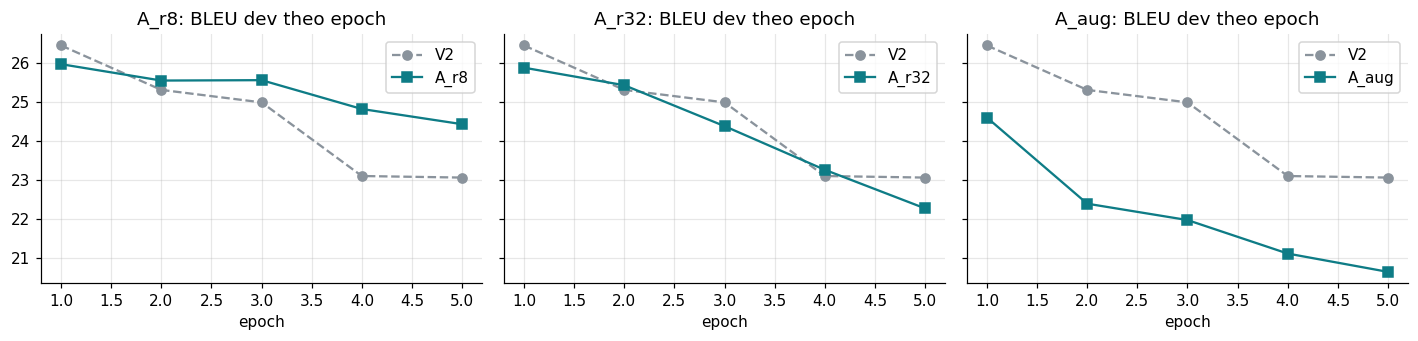

In [14]:
fa = BASE / "reports/ablation/bang_ablation.csv"
if not fa.exists():
    print("NOT RUN: chưa có reports/ablation/bang_ablation.csv (chạy notebooks/03_ablation_va_chon_ban_cuoi.ipynb)")
else:
    display(doc(fa))
    ch_ = J(BASE / "reports/ablation/chon_ban_cuoi.json")
    print("Quy tắc:", ch_["quy_tac"], "| M dev cascade =", ch_["M_dev_cascade"], "| nhóm hoà:", ch_["nhom_hoa"], "| CHỌN:", ch_["ban_chon"])
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
    for a_, k in zip(ax, ("A_r8", "A_r32", "A_aug")):
        e = pd.DataFrame(J(BASE / f"checkpoints/{k}/epochs.json")); v2 = pd.DataFrame(J(BASE / "checkpoints/V2/epochs.json"))
        a_.plot(v2.epoch, v2.dev_BLEU_translate, "o--", color=XAM, label="V2"); a_.plot(e.epoch, e.dev_BLEU_translate, "s-", color=XANH, label=k)
        a_.set_title(f"{k}: BLEU dev theo epoch"); a_.set_xlabel("epoch"); a_.legend()
    plt.tight_layout(); plt.show()